**Import Librabies**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


**Load the Datasets**

In [2]:

df = pd.read_csv(
    r"C:\Users\gupta\Downloads\unemployment in India Dataset\Unemployment in India.csv"
)
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


**3. Data cleaning and preprocessing**

In [3]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df["Date"] = pd.to_datetime(
    df["Date"], dayfirst=True, errors="coerce"
)

numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

required_cols = ["Region", "Date"] + numeric_cols
df = df.dropna(subset=required_cols).copy()


df = df.drop_duplicates()


df = df.sort_values("Date").reset_index(drop=True)

df["Month"] = df["Date"].dt.month_name()
df["Year"] = df["Date"].dt.year

print("Cleaned dataset shape:", df.shape)
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

Missing values:
 Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated E

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Year
count,740,740.000000,7.400000e+02,740.000000,740.000000
mean,2019-12-12 18:36:58.378378496,11.787946,7.204460e+06,42.630122,2019.418919
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000,2019.000000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500,2019.000000
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000,2019.000000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000,2020.000000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000,2020.000000
std,NaN,10.721298,8.087988e+06,8.111094,0.493716


**4. Exploratory data analysis (EDA)**

**A. Average unemployment rate by state**

In [4]:
state_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

display(state_avg.to_frame("Average Unemployment Rate (%)").round(2))

,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


**B. Month-wise unemployment trend**

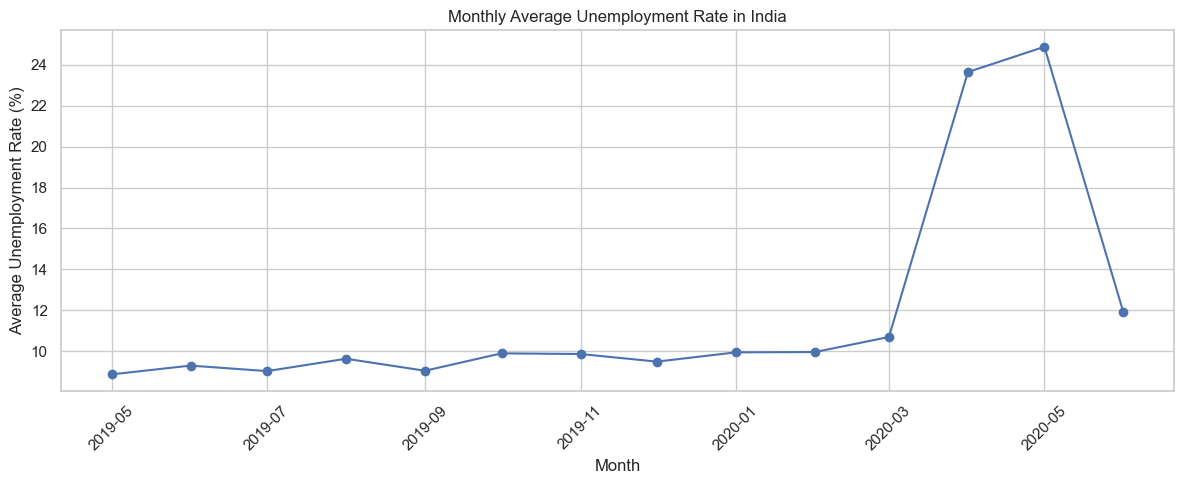

In [5]:
monthly_avg = (
    df.groupby(df["Date"].dt.to_period("M"))[
        "Estimated Unemployment Rate (%)"
    ].mean()
)

monthly_avg.index = monthly_avg.index.to_timestamp()

plt.figure(figsize=(12, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**5. Time-series line chart: Compare three states**

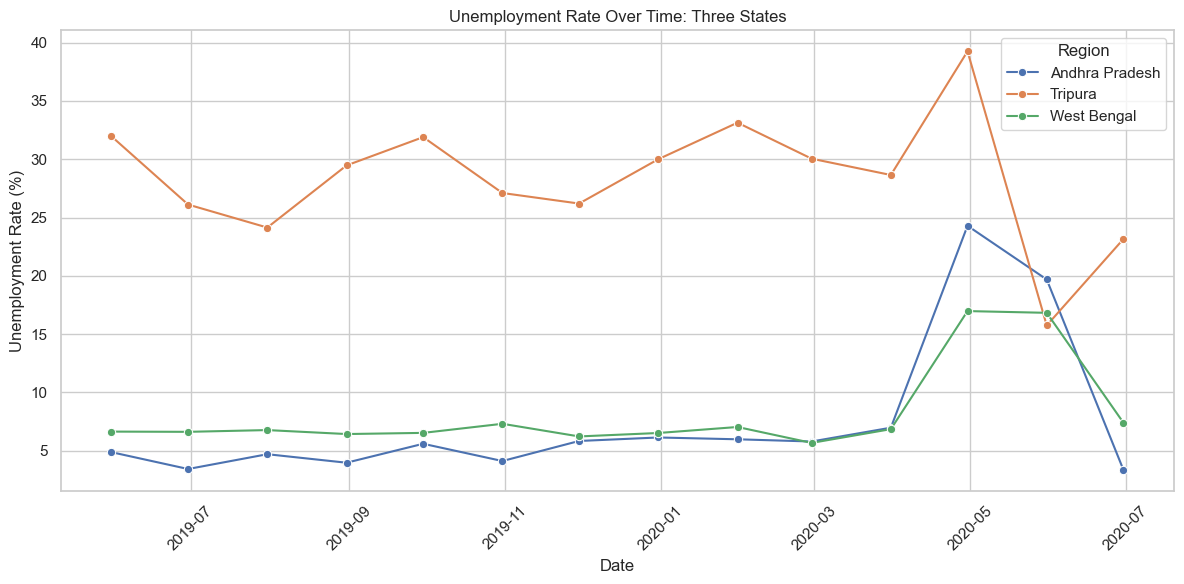

In [6]:
top_states = df["Region"].value_counts().head(3).index.tolist()

state_trend = (
    df[df["Region"].isin(top_states)]
    .groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_trend,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.title("Unemployment Rate Over Time: Three States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**6. Bar chart: Top 10 states with the highest average unemployment**

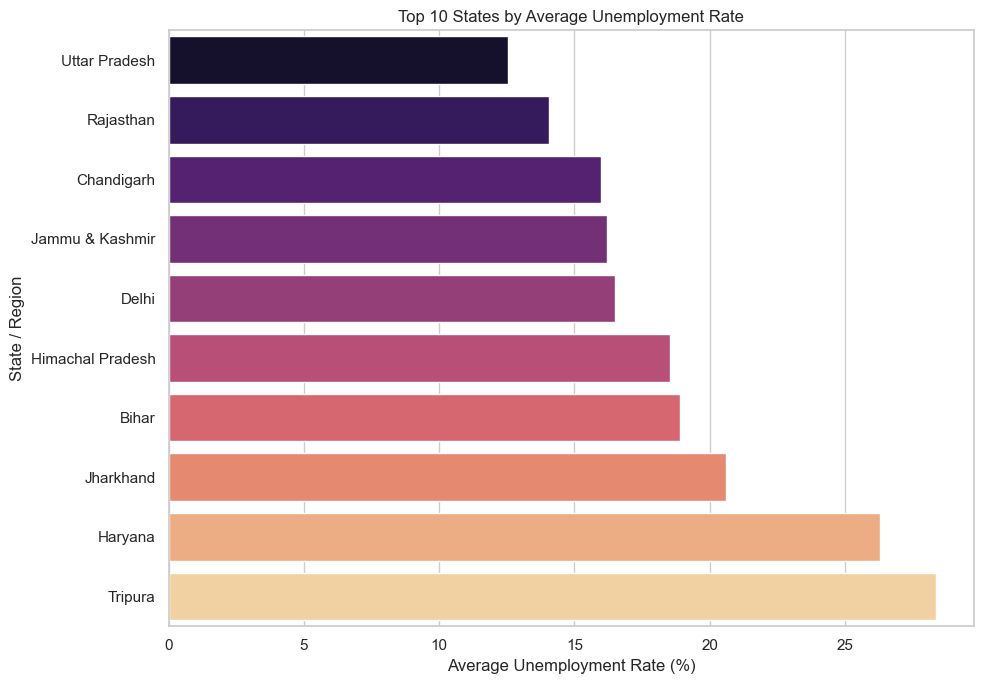

In [7]:
top10 = state_avg.head(10).sort_values()

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top10.values,
    y=top10.index,
    hue=top10.index,
    palette="magma",
    legend=False
)

plt.title("Top 10 States by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State / Region")
plt.tight_layout()
plt.show()

**7. Heatmap: Correlation between labour-market indicators**

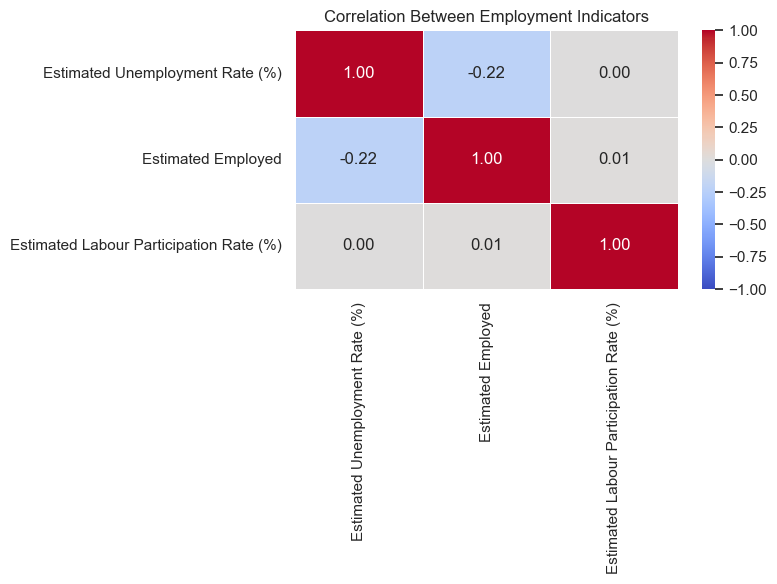

In [8]:
corr_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[corr_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

**8. Pre-COVID vs. post-COVID comparison**

*For a simple comparison, use March 2020 as the dividing point. Treat January 2019 through February 2020 as the pre-COVID baseline and March 2020 onward as the COVID-period comparison. March is a transition month, so the split is an analytical choice rather than a precise measure of when the pandemic began.*

In [10]:
df["Period"] = np.where(
    df["Date"] < pd.Timestamp("2020-03-01"),
    "Pre-COVID",
    "COVID period"
)

comparison = (
    df.groupby("Period")[
        [
            "Estimated Unemployment Rate (%)",
            "Estimated Employed",
            "Estimated Labour Participation Rate (%)"
        ]
    ]
    .mean()
)

display(comparison.round(2))

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Period,,,
COVID period,17.77,6517203.34,39.33
Pre-COVID,9.51,7466027.87,43.89


**Visualize the comparison**

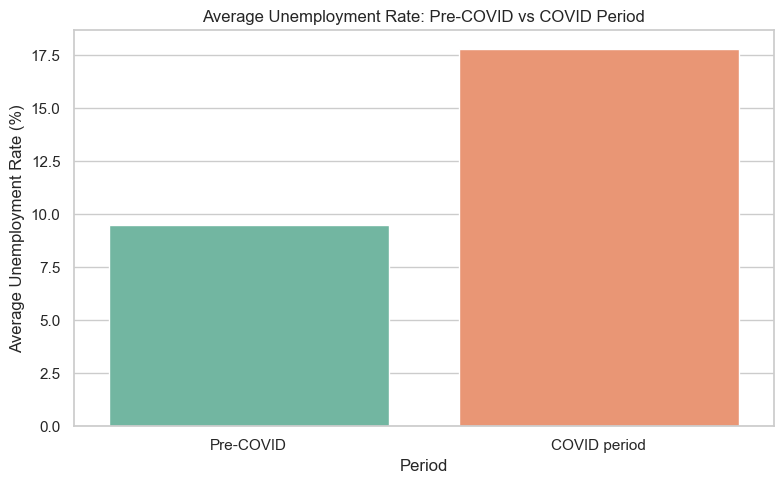

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Period",
    y="Estimated Unemployment Rate (%)",
    hue="Period",
    palette="Set2",
    errorbar=None,
    legend=False
)

plt.title("Average Unemployment Rate: Pre-COVID vs COVID Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

**Calculate the absolute and percentage change:**

In [12]:
pre = comparison.loc["Pre-COVID", "Estimated Unemployment Rate (%)"]
during = comparison.loc["COVID period", "Estimated Unemployment Rate (%)"]

print(f"Pre-COVID average: {pre:.2f}%")
print(f"COVID-period average: {during:.2f}%")
print(f"Absolute change: {during - pre:.2f} percentage points")

if pre != 0:
    print(f"Relative change: {((during - pre) / pre) * 100:.2f}%")

Pre-COVID average: 9.51%
COVID-period average: 17.77%
Absolute change: 8.26 percentage points
Relative change: 86.91%


**9. Final project conclusion**

*Use this as a conclusion template in your notebook. Fill in the blanks using the actual results from your charts and tables.*

**Conclusion: Unemployment Analysis with Python**

This project examined unemployment trends across Indian states and regions using Python, pandas, Matplotlib, and Seaborn.

The exploratory data analysis identified differences in average unemployment rates across states and changes in unemployment over time. The time-series visualization was used to examine the unemployment trends surrounding the COVID-19 lockdown period.

The pre-COVID and COVID-period comparison showed a difference of [enter calculated change] percentage points in the average unemployment rate. The correlation heatmap helped explore relationships among unemployment, employment, and labour-force participation indicators.

Overall, the analysis demonstrates how data visualization and statistical summaries can help identify regional disparities and historical labour-market changes. The findings should be interpreted in the context of the dataset's limited historical period and should not be treated as proof of causation or as a representation of current unemployment conditions.